In [0]:
%sql

SELECT
    review_score AS nota,
    COUNT(*) AS quantidade_avaliacoes,
    ROUND(
        100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
        2
    ) AS percentual
FROM olist_dw.dw.order_reviews
WHERE review_score BETWEEN 1 AND 5
GROUP BY review_score
ORDER BY review_score;


nota,quantidade_avaliacoes,percentual
1,11424,11.51
2,3151,3.18
3,8179,8.24
4,19142,19.29
5,57328,57.78


In [0]:
%sql

WITH reviews_by_order AS (
    SELECT
        order_id,
        AVG(review_score) AS nota_media_pedido,
        COUNT(*) AS quantidade_avaliacoes
    FROM olist_dw.dw.order_reviews
    WHERE review_score BETWEEN 1 AND 5
    GROUP BY order_id
),

delivery_classification AS (
    SELECT
        order_id,
        CASE
            WHEN order_delivered_customer_date >
                 order_estimated_delivery_date
                THEN 'Com atraso'
            ELSE 'No prazo'
        END AS status_entrega
    FROM olist_dw.dw.fact_delivery_metrics
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_estimated_delivery_date IS NOT NULL
)

SELECT
    dc.status_entrega,
    COUNT(*) AS quantidade_pedidos,
    ROUND(AVG(r.nota_media_pedido), 2) AS nota_media,
    ROUND(AVG(r.quantidade_avaliacoes), 2) AS avaliacoes_por_pedido
FROM delivery_classification dc
INNER JOIN reviews_by_order r
    ON dc.order_id = r.order_id
GROUP BY dc.status_entrega
ORDER BY dc.status_entrega;


status_entrega,quantidade_pedidos,nota_media,avaliacoes_por_pedido
Com atraso,7661,2.57,1.01
No prazo,88163,4.29,1.01


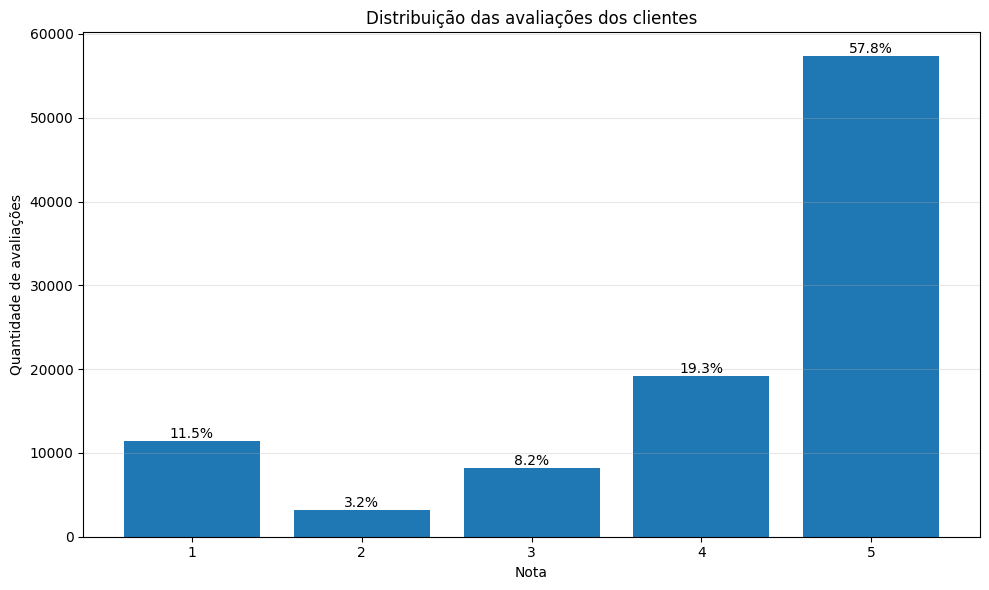

In [0]:
import matplotlib.pyplot as plt

df_reviews = spark.sql("""
    SELECT
        review_score AS nota,
        COUNT(*) AS quantidade,
        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS percentual
    FROM olist_dw.dw.order_reviews
    WHERE review_score BETWEEN 1 AND 5
    GROUP BY review_score
    ORDER BY review_score
""").toPandas()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    df_reviews["nota"].astype(str),
    df_reviews["quantidade"]
)

plt.title("Distribuição das avaliações dos clientes")
plt.xlabel("Nota")
plt.ylabel("Quantidade de avaliações")

for bar, percentual in zip(bars, df_reviews["percentual"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentual:.1f}%",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/distribuicao_notas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


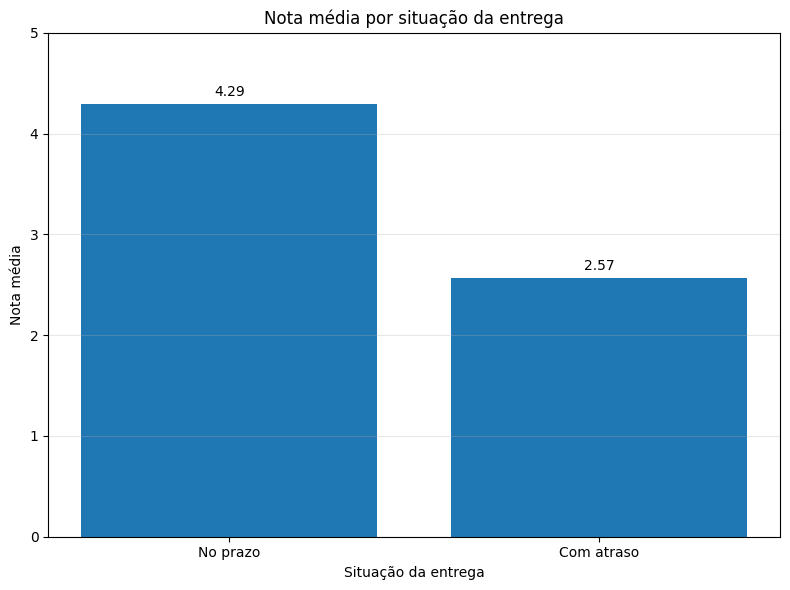

In [0]:

import matplotlib.pyplot as plt

df_satisfaction = spark.sql("""
    WITH reviews_by_order AS (
        SELECT
            order_id,
            AVG(review_score) AS nota_media_pedido
        FROM olist_dw.dw.order_reviews
        WHERE review_score BETWEEN 1 AND 5
        GROUP BY order_id
    ),
    delivery_classification AS (
        SELECT
            order_id,
            CASE
                WHEN order_delivered_customer_date >
                     order_estimated_delivery_date
                THEN 'Com atraso'
                ELSE 'No prazo'
            END AS status_entrega
        FROM olist_dw.dw.fact_delivery_metrics
        WHERE order_status = 'delivered'
          AND order_delivered_customer_date IS NOT NULL
          AND order_estimated_delivery_date IS NOT NULL
    )
    SELECT
        dc.status_entrega,
        AVG(r.nota_media_pedido) AS nota_media,
        COUNT(*) AS quantidade_pedidos
    FROM delivery_classification dc
    INNER JOIN reviews_by_order r
        ON dc.order_id = r.order_id
    GROUP BY dc.status_entrega
""").toPandas()

plt.figure(figsize=(8, 6))

bars = plt.bar(
    df_satisfaction["status_entrega"],
    df_satisfaction["nota_media"]
)

plt.title("Nota média por situação da entrega")
plt.xlabel("Situação da entrega")
plt.ylabel("Nota média")
plt.ylim(0, 5)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{bar.get_height():.2f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/nota_media_atraso.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
